**This notebook is to visualize the disportion of the dataset, and check if there's umblanced data so we can see or pick a strategy to split the dataset into training and test set**

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## **Collect the CSV annotations files**

In [6]:
base_path = r"C:\Users\aliai\Desktop\M2 I2A\Optimisation des modeles - Ouzar\Projet\Dataset\annotations\updated"
training_folders_names = ["training-a", "training-b", "training-c", "training-d", "training-e", "training-f"]
file_name = "REFERENCE_withSQI.csv"

#### **Function to count the number of classes**

In [33]:
def count_number_of_classes(data : pd.DataFrame, index : int, class_ref : int) -> int :
    counts = data[data[index] == class_ref].shape[0]
    return counts

In [119]:
counts = []
data = np.empty((0, 4))  # 0 rows, 3 columns
for training_folder in training_folders_names : 
    path = base_path + f"\\{training_folder}\\{file_name}"
    data_file = pd.read_csv(path, header=None)
    data_file["training_set"] = training_folder
    data = np.append(data,np.array(data_file),axis=0)
    data_count = {
    "number of normal" : count_number_of_classes(data_file, 1, 1) ,
    "number of abnormal" : count_number_of_classes(data_file, 1, -1) ,
    "number of unsure" : count_number_of_classes(data_file, 2, 0),
    "total sure" : count_number_of_classes(data_file, 2, 1),
    "training set" : training_folder
    }

    counts.append(data_count)

#### **Visualize the data distribution between classes**

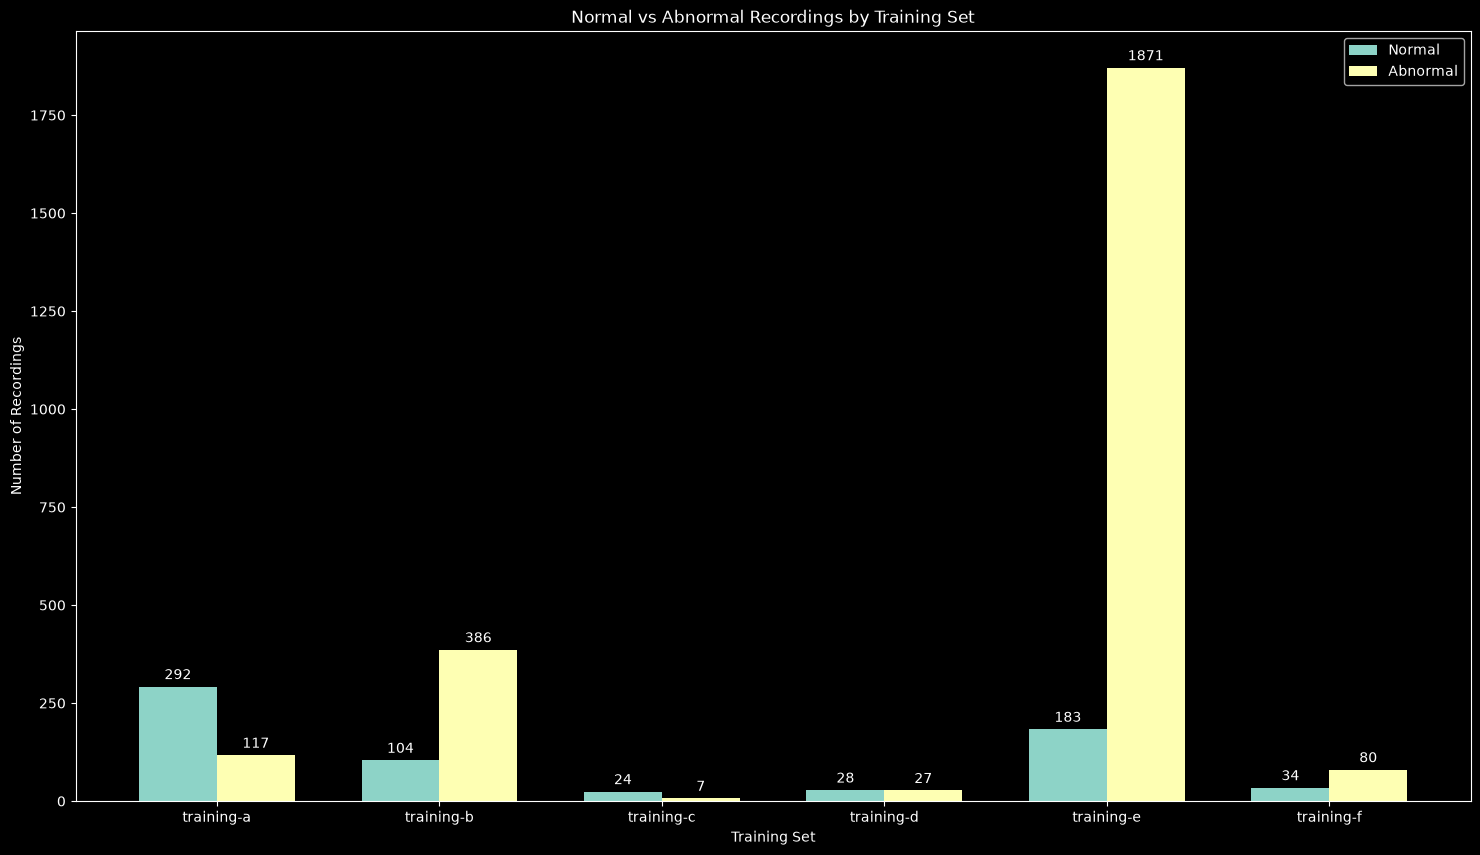

In [ ]:
# Extract values
training_set = [item["training set"] for item in counts]
normal = [item["number of normal"] for item in counts]
abnormal = [item["number of abnormal"] for item in counts]
unsure = [item["number of unsure"] for item in counts]
sure = [item["total sure"] for item in counts]
x = np.arange(len(training_set))
width = 0.35

fig, ax = plt.subplots(figsize=(18, 10))

bars_normal = ax.bar(x - width / 2, normal, width, label='Normal')
bars_abnormal = ax.bar(x + width / 2, abnormal, width, label='Abnormal')

ax.bar_label(bars_normal, padding=3)
ax.bar_label(bars_abnormal, padding=3)

ax.set_xticks(x)
ax.set_xticklabels(training_set)
ax.set_xlabel('Training Set')
ax.set_ylabel('Number of Recordings')
ax.set_title('Normal vs Abnormal Recordings by Training Set')
ax.legend()

#### **Visulize the data distribution between sure signals and unsure signals**

<bound method Figure.show of <Figure size 1800x1000 with 1 Axes>>

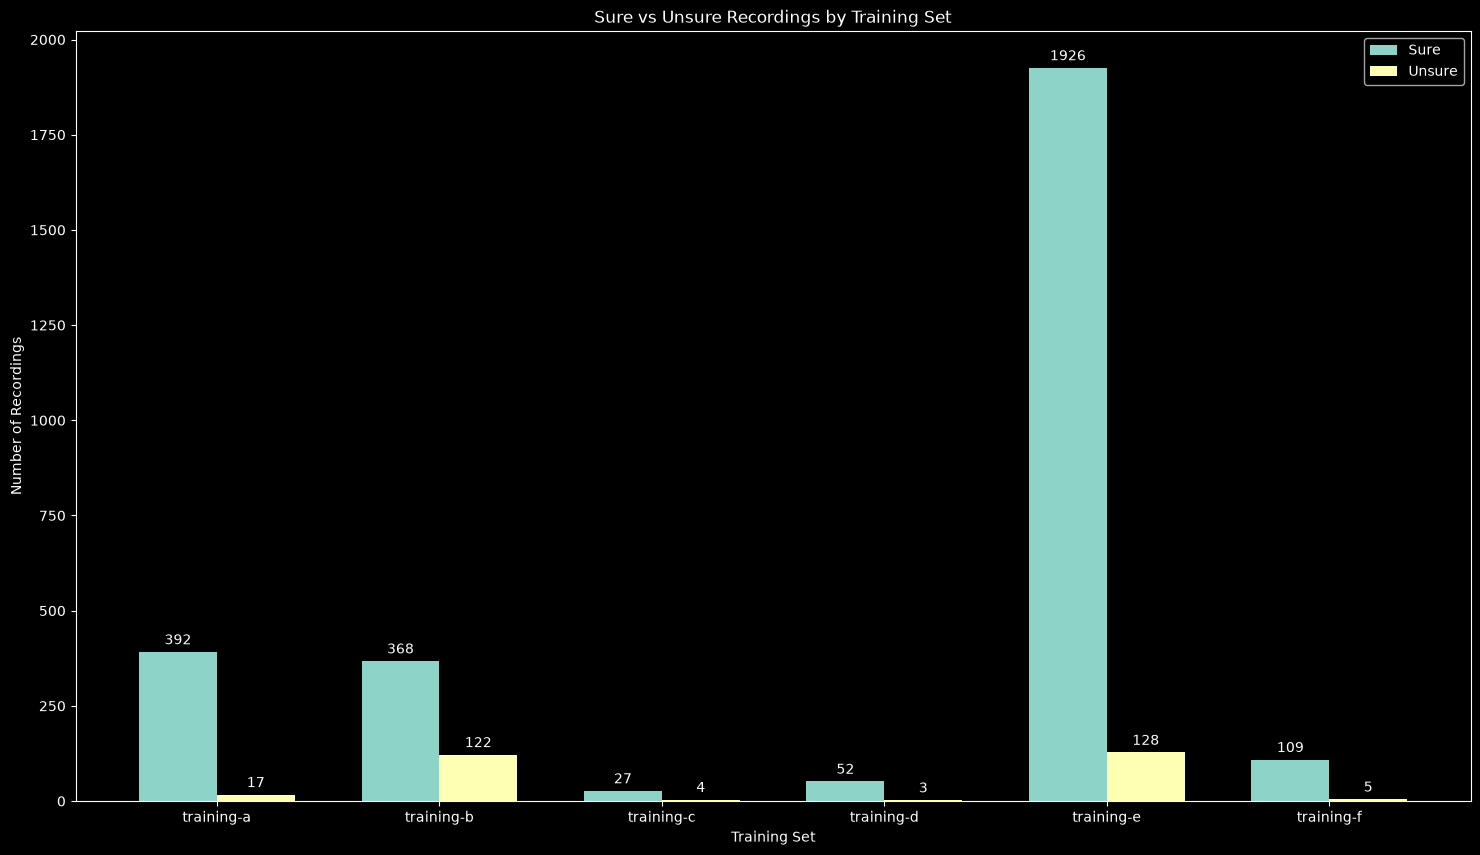

In [95]:
x = np.arange(len(training_set))
width = 0.35

fig, ax = plt.subplots(figsize=(18, 10))

bars_sure = ax.bar(x - width / 2, sure, width, label='Sure')
bars_unsure = ax.bar(x + width / 2, unsure, width, label='Unsure')

ax.bar_label(bars_sure, padding=3)
ax.bar_label(bars_unsure, padding=3)
# ax.bar_label(bars_unsure, padding=3)

ax.set_xticks(x)
ax.set_xticklabels(training_set)
ax.set_xlabel('Training Set')
ax.set_ylabel('Number of Recordings')
ax.set_title('Sure vs Unsure Recordings by Training Set')
ax.legend()
fig.show

#### **Removing the unsure data**

In [121]:
data = pd.DataFrame(data)
data = data[data[2] == 1]
annotations = data

In [122]:
annotations

,0,1,2,3
0,a0001,1,1,training-a
1,a0002,1,1,training-a
2,a0003,1,1,training-a
3,a0004,1,1,training-a
4,a0005,1,1,training-a
...,...,...,...,...
3148,f0110,-1,1,training-f
3149,f0111,-1,1,training-f
3150,f0112,-1,1,training-f
3151,f0113,-1,1,training-f
